In [1]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
import os
import PIL
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

from NNre import Y_train

I0000 00:00:1781876567.371997   17081 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1781876567.419578   17081 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1781876569.178296   17081 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
dataset_url =  "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url, cache_dir="Data/", untar=True)

In [3]:
data_dir

'Data/datasets/flower_photos'

In [4]:
import  pathlib
data_dir = pathlib.Path(data_dir)
data_dir

PosixPath('Data/datasets/flower_photos')

In [5]:
image_count = len(list(data_dir.glob('**/*.jpg')))
image_count

3670

In [6]:
roses = list(data_dir.glob('flower_photos/roses/*'))
roses[:5]

[PosixPath('Data/datasets/flower_photos/flower_photos/roses/12240577184_b0de0e53ea_n.jpg'),
 PosixPath('Data/datasets/flower_photos/flower_photos/roses/19988406792_68201f76e3_n.jpg'),
 PosixPath('Data/datasets/flower_photos/flower_photos/roses/2675221506_5286c0595f.jpg'),
 PosixPath('Data/datasets/flower_photos/flower_photos/roses/2300959680_8d22fa5ee2.jpg'),
 PosixPath('Data/datasets/flower_photos/flower_photos/roses/3576488381_611f3446e0_n.jpg')]

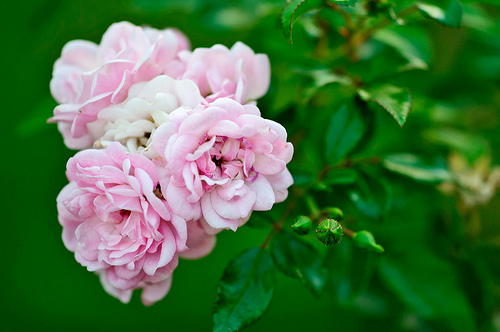

In [7]:
PIL.Image.open(str(roses[7]))

In [8]:
flowers_images_dict = {
'roses': list(data_dir.glob('flower_photos/roses/*')),
'daisy': list(data_dir.glob('flower_photos/daisy/*')),
'dandelion': list(data_dir.glob('flower_photos/dandelion/*')),
'sunflowers': list(data_dir.glob('flower_photos/sunflowers/*')),
'tulips': list(data_dir.glob('flower_photos/tulips/*')),
}

In [9]:
flowers_images_dict['daisy']

[PosixPath('Data/datasets/flower_photos/flower_photos/daisy/4993492878_11fd4f5d12.jpg'),
 PosixPath('Data/datasets/flower_photos/flower_photos/daisy/1344985627_c3115e2d71_n.jpg'),
 PosixPath('Data/datasets/flower_photos/flower_photos/daisy/3117644024_1cbb59a509_n.jpg'),
 PosixPath('Data/datasets/flower_photos/flower_photos/daisy/9158041313_7a6a102f7a_n.jpg'),
 PosixPath('Data/datasets/flower_photos/flower_photos/daisy/175106495_53ebdef092_n.jpg'),
 PosixPath('Data/datasets/flower_photos/flower_photos/daisy/3552074420_2a0a7166db_m.jpg'),
 PosixPath('Data/datasets/flower_photos/flower_photos/daisy/2877860110_a842f8b14a_m.jpg'),
 PosixPath('Data/datasets/flower_photos/flower_photos/daisy/695778683_890c46ebac.jpg'),
 PosixPath('Data/datasets/flower_photos/flower_photos/daisy/102841525_bd6628ae3c.jpg'),
 PosixPath('Data/datasets/flower_photos/flower_photos/daisy/8964198962_6d8593b533.jpg'),
 PosixPath('Data/datasets/flower_photos/flower_photos/daisy/4897587985_f9293ea1ed.jpg'),
 PosixPath('

In [10]:
flower_labels_dict = {
    'roses': 0,
    'daisy': 1,
    'dandelion': 2,
    'sunflowers': 3,
    'tulips': 4
}

In [11]:
img = cv2.imread(flowers_images_dict['roses'][0])
img

array([[[ 73, 112,  80],
        [ 70, 109,  77],
        [ 65, 104,  72],
        ...,
        [  5,  88,  80],
        [  0,  82,  73],
        [  0,  78,  66]],

       [[ 72, 110,  80],
        [ 69, 107,  77],
        [ 65, 103,  73],
        ...,
        [  2,  79,  71],
        [  0,  74,  63],
        [  0,  70,  58]],

       [[ 71, 109,  79],
        [ 70, 108,  78],
        [ 64, 105,  74],
        ...,
        [  1,  70,  60],
        [  3,  64,  54],
        [  0,  60,  49]],

       ...,

       [[  1,   1,   1],
        [  1,   1,   1],
        [  0,   0,   0],
        ...,
        [  2,  22,   9],
        [  1,  24,  10],
        [  0,  25,  11]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  3,  21,   8],
        [  0,  23,   9],
        [  0,  23,   9]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  5,  23,  10],
        [  1,  24,  10],
        [  0,  23,   9]]

In [12]:
img.shape

(247, 320, 3)

In [13]:
cv2.resize(img, (180,180)).shape

(180, 180, 3)

In [14]:
X, y = [], []
for flower_name, images in flowers_images_dict.items():
    for image in images:
        img = cv2.imread(str(image))
        resized_img = cv2.resize(img, (180, 180))
        X.append(resized_img)
        y.append(flower_labels_dict[flower_name])

In [15]:
X = np.array(X)
y = np.array(y)

In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

In [17]:
X_train_scaled = X_train/255
X_test_scaled = X_test/255

In [18]:
num_classes = 5

model = Sequential([
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes)
])

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

I0000 00:00:1781876582.534623   17081 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3617 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


In [21]:
model.fit(X_train_scaled, y_train, epochs=30)

Epoch 1/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9255 - loss: 0.2365
Epoch 2/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9597 - loss: 0.1364
Epoch 3/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9767 - loss: 0.0936
Epoch 4/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9818 - loss: 0.0578
Epoch 5/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9851 - loss: 0.0497
Epoch 6/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9931 - loss: 0.0260
Epoch 7/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.9982 - loss: 0.0106
Epoch 8/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 1.0000 - loss: 0.0033
Epoch 9/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 1.0000 - loss: 0.0015
Epoch 10/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 1.0000 - loss: 8.6435e-04
Epoch 11/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 1.0000 - loss: 6.3284e-04
Epoch 12/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - a

In [22]:
model.evaluate(X_test_scaled, y_test)

29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.6253 - loss: 3.6488


[3.6488234996795654, 0.6252723336219788]

In [23]:
predictions = model.predict(X_test_scaled)
predictions

29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


array([[ -2.3524904 ,  19.31321   , -12.028832  , -23.688133  ,
         -4.9423833 ],
       [ 10.997351  ,   3.9314575 , -11.0381365 , -27.715694  ,
         -6.430138  ],
       [ -3.5237548 ,  -6.5853205 ,  10.189048  , -16.656218  ,
         -3.0824397 ],
       ...,
       [ -4.7516193 , -17.307396  ,  -2.7518451 ,  28.444386  ,
         -0.26309615],
       [  4.974134  ,  -9.9521055 , -11.315229  , -14.597167  ,
          0.6492445 ],
       [ -2.9207094 ,  -3.7793815 ,   3.126204  ,  11.863869  ,
        -10.08539   ]], shape=(918, 5), dtype=float32)

In [25]:
score = tf.nn.softmax(predictions[0])
score

<tf.Tensor: shape=(5,), dtype=float32, numpy=
array([3.8967854e-10, 1.0000000e+00, 2.4452572e-14, 2.1122927e-19,
       2.9236818e-11], dtype=float32)>

In [26]:
np.argmax(score)

np.int64(1)

In [27]:
y_test[0]

np.int64(1)

In [40]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", input_shape=(180,180,3)),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

/home/vansh/ML/lib/python3.12/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [34]:
X_trial = X[:10]

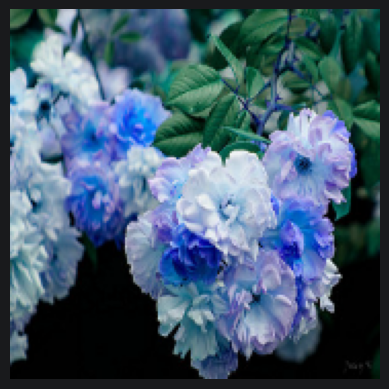

In [35]:
plt.axis('off')
plt.imshow(X_trial[0])

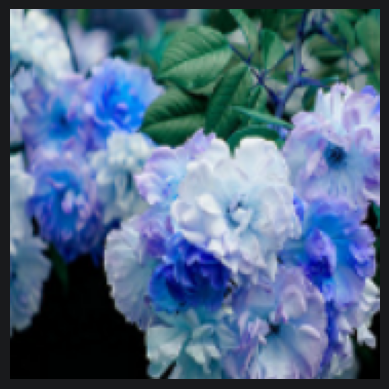

In [39]:
plt.axis('off')
plt.imshow(data_augmentation(X_trial)[0].numpy().astype("uint8"))

In [42]:
num_classes = 5

model = Sequential([
    data_augmentation,
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes)
])

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [ ]:
model.fit(X_train_scaled, y_train, epochs=30)

In [44]:
os.environ['TF_GPU_ALLOCATOR'] = 'cuda_malloc_async'